# 05 — Második intelligenciaréteg: tematikus kategorizálás / Layer 2: thematic categorisation

HU: Az első réteg megmondja, **milyen** egy mondat (negatív / semleges / pozitív). A második réteg két szinten
mondja meg, **miről** és **pontosan mi miatt**:

```
mondat ──► [1. réteg] szentiment (B)              → negatív / semleges / pozitív
       ──► [2/a] aspektus-osztályozó (HRAST, BERT) → MIRŐL szól?   pl. bathroom
       ──► [2/b] altémák (beágyazás + fürtözés)    → MI A GOND?    pl. „nincs meleg víz”
```

| # | Lépés / Step | Mérés / Measurement | Dolgozat / Thesis |
|---|---|---|---|
| 1 | 2/a tanítás a HRAST-on / training on HRAST | aspektusonkénti F1 a HRAST-teszten, vs. kulcsszólista | 3.4, 3.5 |
| 2 | 2/a alkalmazás a Booking-mondatokra / applying to Booking | egyezés a kulcsszólistával | 3.5 |
| 3 | 2/b altémák aspektusonként / subtopics per aspect | NPMI-koherencia, diverzitás, stabilitás (ARI) | 3.4, 3.5 |
| 4 | Panasztérkép / complaint map | lift szegmensenként | 3.5 |
| 5 | Kézi ellenőrzés / manual check | témánkénti pontosság | 3.5 |

**Előfeltétel / Prerequisites:** a (B) modell (`results/models/approach_b_hrast`), a HRAST CSV a `data/raw/hrast/`
mappában, és `pip install sentence-transformers umap-learn`.
**Elemzési egység / Analysis unit:** tagmondat, a dicséret- és panaszmezőből KÜLÖN bontva / clause, split SEPARATELY
from the praise and complaint fields. GPU ajánlott (a 2/a tanítás kb. 10–15 perc).

## 1. Környezet és adatok / Environment and data

In [1]:
# HU: A notebooks/ mappából futunk, ezért a szülőmappát a path-hoz adjuk (src csomag).
# EN: We run from the notebooks/ folder, so the parent folder is added to the path (src package).
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import set_seed
from src.config import CFG, PATHS, SENTIMENT_COLORS, INK, APPROACHES, apply_plot_style
from src import data_loading as dl
from src import preprocessing as pp
from src import evaluation as ev
from src import descriptives as ds
from src import aspects as asp
from src import aspect_model as am
from src import topic_modeling as tm
from src import pipeline

# HU: Reprodukálhatóság + egységes ábrastílus. / EN: Reproducibility + uniform figure style.
set_seed()
PATHS.ensure()
apply_plot_style()
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 170)

# HU: ELEMZÉSI EGYSÉGEK: a dicséret- és a panaszmezőt KÜLÖN bontjuk tagmondatokra (pont, pontosvessző,
#     "but / however / although" mentén), így a kettő nem olvad egy "mondatba". A dicséretmezőben a
#     vesszős felsorolásokat is szétbontjuk (CFG.split_praise_lists). Minden egységre lefut a
#     (B) modell is (kb. 5–10 perc, darabolva, folytatható).
# EN: ANALYSIS UNITS: the praise and the complaint field are split into clauses SEPARATELY (at full stops,
#     semicolons, "but / however / although"), so the two never merge into one "sentence". In the praise
#     field comma enumerations are split too (CFG.split_praise_lists). The (B) model also runs on every
#     unit (about 5–10 min, chunked, resumable).
from src import bert_labelling as bl
meta = ds.prepare_star_rating(dl.read_frame(pipeline.LABELLED))
units = pp.build_field_units(meta)
scorer_b = bl.TransformerScorer(str(PATHS.models / "approach_b_hrast"))
sent = bl.predict_units(units, "", "B", cache_name="B_field_units", scorer=scorer_b)

meta_cols = ["review_id", "score", "label_final", "accommodation_type", "accommodation_country",
             "guest_type", "accommodation_star_rating"]
sent = sent.merge(meta[[c for c in meta_cols if c in meta.columns]], on="review_id", how="left")
dl.write_frame(sent, PATHS.labels / "field_units_B")
print(f"{len(sent):,} units from {sent['review_id'].nunique():,} reviews")

# HU: Mezőpolaritás × (B)-címke: mennyire ért egyet a modell a vendég saját besorolásával?
# EN: Field polarity × (B) label: how far does the model agree with the guest's own classification?
display(pd.crosstab(sent["field_polarity"], sent["B_label"], normalize="index").round(3))

15:45:24 | INFO    | src.preprocessing | Field units: 108161 from 19969 reviews | by field: {'positive': 81420, 'negative': 26741}
15:45:56 | INFO    | src.bert_labelling | Loading model: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\models\approach_b_hrast (device: cuda, fp16: True)


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

15:46:01 | INFO    | src.bert_labelling | Model type: 3class | labels: ['negative', 'neutral', 'positive']
15:46:01 | WARNING | src.bert_labelling | Cache 'B_field_units' is stale (input or model changed) — recomputing.
15:46:01 | INFO    | src.bert_labelling | [B_field_units] chunk 1/11 (10000 texts)
15:46:04 | INFO    | src.bert_labelling |   C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\models\approach_b_hrast: 50/157 batches (958 texts/s)
15:46:07 | INFO    | src.bert_labelling |   C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\models\approach_b_hrast: 100/157 batches (1139 texts/s)
15:46:09 | INFO    | src.bert_labelling |   C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\models\approach_b_hrast: 150/157 batches (1188 texts/s)
15:46:10 | INFO    | src.bert_labelling | [B_field_units] chunk 2/11 (10000 texts)
15:46:12 | INFO    | src.bert_labelling |   C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\

108,161 units from 19,969 reviews


B_label,negative,neutral,positive
field_polarity,,,
negative,0.737,0.079,0.184
positive,0.067,0.049,0.884


## 2. 2/a — Aspektus-osztályozó a HRAST-on / Aspect classifier on HRAST

HU: Többcímkés BERT: aspektusonként egy igen/nem döntés (szigmoid). A ritka aspektusok nagyobb súlyt kapnak
(`pos_weight`), a döntési küszöböt aspektusonként a **validációs** halmazon hangoljuk, a végső mérés a **teszthalmazon**
történik — és ugyanott mérjük a kulcsszólistát is (alapvonal).

EN: Multi-label BERT: one yes/no decision per aspect (sigmoid). Rare aspects get a larger weight (`pos_weight`), the
decision threshold is tuned per aspect on the **validation** set, the final measurement is on the **test** set — where
the keyword list (baseline) is measured too.

In [2]:
hrast_raw = dl.load_hrast_raw()
asp_data, ASPECTS = am.prepare_hrast_aspects(hrast_raw)
counts = asp_data[ASPECTS].sum().sort_values(ascending=False).to_frame("sentences")
counts["share"] = (counts["sentences"] / len(asp_data)).round(4)
display(counts); ev.save_table(counts, "05_hrast_aspect_counts")

15:47:27 | INFO    | src.data_loading | HRAST loaded: hrast.csv — 23113 rows, columns: ['id', 'review', 'Unnamed: 2', 'positive', 'negative', 'neutral', 'Clean', 'Comfort', 'Facilities/Amenities', 'Location', 'Restaurant (dinner)', 'Staff', 'View (Balcony)', 'Breakfast', 'Room', 'Pool', 'Beach', 'Bathroom/Shower (toilet)', 'Bar', 'Bed', 'Parking', 'Noise', 'Reception-checkin', 'Lift', 'Value for money', 'Wi-Fi', 'Generic', 'Aspect']
15:47:27 | INFO    | src.aspect_model | HRAST aspect data: 23105 sentences, 21 aspects | without aspect: 0.0%


,sentences,share
room,5004,0.2166
location,4727,0.2046
staff,3800,0.1645
cleanliness,2926,0.1266
facilities,2923,0.1265
comfort,2561,0.1108
breakfast,2539,0.1099
bathroom,2344,0.1014
generic,1973,0.0854
noise,1604,0.0694


15:47:27 | INFO    | src.evaluation | Table saved: 05_hrast_aspect_counts.csv


WindowsPath('C:/Users/seszt/Documents/BCE/7_felev/Szakdolgozat/THESIS/CODE/results/tables/05_hrast_aspect_counts.csv')

Aspect model already trained — loading the saved test results.


,precision,recall,f1,support
room,0.7927,0.7906,0.7917,769
location,0.9348,0.9556,0.9451,675
staff,0.9193,0.9597,0.9391,546
cleanliness,0.9417,0.9417,0.9417,446
facilities,0.8479,0.8064,0.8266,470
comfort,0.8282,0.8258,0.8270,356
breakfast,0.9280,0.9704,0.9488,372
bathroom,0.9520,0.9242,0.9379,343
generic,0.7085,0.7864,0.7454,309
noise,0.9466,0.9323,0.9394,266


,support,keyword_precision,keyword_recall,keyword_f1,model_precision,model_recall,model_f1,f1_gain
aspect,,,,,,,,
room,769,0.5673,0.8986,0.6955,0.7927,0.7906,0.7917,0.0961
location,675,0.9282,0.9007,0.9143,0.9348,0.9556,0.9451,0.0308
staff,546,0.9022,0.8443,0.8723,0.9193,0.9597,0.9391,0.0668
facilities,470,0.5340,0.3511,0.4236,0.8479,0.8064,0.8266,0.4030
cleanliness,446,0.9332,0.7825,0.8512,0.9417,0.9417,0.9417,0.0905
breakfast,372,0.8589,0.9489,0.9017,0.9280,0.9704,0.9488,0.0471
bathroom,343,0.8963,0.9067,0.9014,0.9520,0.9242,0.9379,0.0364
noise,266,0.9755,0.7481,0.8468,0.9466,0.9323,0.9394,0.0926
value_for_money,136,0.6788,0.6838,0.6813,0.6894,0.8162,0.7475,0.0662


15:47:28 | INFO    | src.evaluation | Figure saved: 05_aspect_keyword_vs_model.png


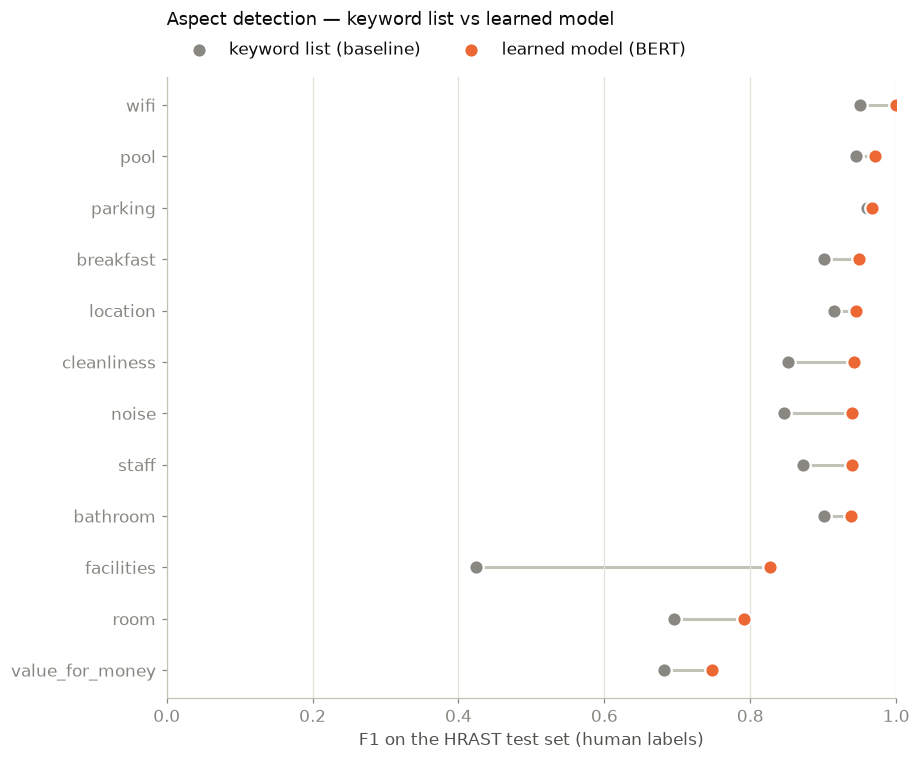

Mean F1 on the shared aspects — keyword: 0.829 | model: 0.913


In [3]:
# HU: Ha a modell már elkészült, nem tanítjuk újra (a mentett teszteredményt töltjük be).
# EN: If the model already exists it is not retrained (the saved test results are loaded).
if not (am.DEFAULT_MODEL_DIR / "thresholds.json").exists():
    result = am.train_aspect_model(asp_data, ASPECTS)
    report, comparison = result["test_report"], result["keyword_comparison"]
    ev.save_table(report, "05_aspect_model_test_report")
    ev.save_table(comparison, "05_aspect_keyword_vs_model")
else:
    print("Aspect model already trained — loading the saved test results.")
    report = pd.read_csv(PATHS.tables / "05_aspect_model_test_report.csv", index_col=0)
    comparison = pd.read_csv(PATHS.tables / "05_aspect_keyword_vs_model.csv", index_col=0)

display(report)
display(comparison)
am.plot_keyword_vs_model(comparison, save_as="05_aspect_keyword_vs_model"); plt.show()
print(f"Mean F1 on the shared aspects — keyword: {comparison['keyword_f1'].mean():.3f} | "
      f"model: {comparison['model_f1'].mean():.3f}")

## 3. 2/a alkalmazása a Booking-mondatokra / Applying 2/a to the Booking sentences

HU: Darabolt, folytatható futás (mint a címkézésnél). Itt nincs emberi címke, ezért a kulcsszólistával való
**egyezést** mérjük (konzisztencia), nem a pontosságot.
EN: Chunked, resumable run (as in labelling). There is no human label here, so we measure **agreement** with the
keyword list (consistency), not accuracy.

In [4]:
sent_asp = am.predict_aspects(sent, cache_name="aspects_field_units")
dl.write_frame(sent_asp, PATHS.labels / "field_units_aspects")
ASPECT_NAMES = am.aspect_names_in(sent_asp)

share = sent_asp[[f"asp_{a}" for a in ASPECT_NAMES]].mean().sort_values(ascending=False)
share.index = share.index.str.replace("asp_", "", regex=False)
display(share.round(4).to_frame("share of sentences"))
print(f"Sentences without any aspect: {(sent_asp['n_aspects'] == 0).mean():.1%}")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

15:47:30 | WARNING | src.bert_labelling | Cache 'aspects_field_units' is stale (input or model changed) — recomputing.
15:47:30 | INFO    | src.bert_labelling | [aspects_field_units] chunk 1/11 (10000 texts)
15:47:38 | INFO    | src.bert_labelling | [aspects_field_units] chunk 2/11 (10000 texts)
15:47:46 | INFO    | src.bert_labelling | [aspects_field_units] chunk 3/11 (10000 texts)
15:47:53 | INFO    | src.bert_labelling | [aspects_field_units] chunk 4/11 (10000 texts)
15:48:01 | INFO    | src.bert_labelling | [aspects_field_units] chunk 5/11 (10000 texts)
15:48:08 | INFO    | src.bert_labelling | [aspects_field_units] chunk 6/11 (10000 texts)
15:48:15 | INFO    | src.bert_labelling | [aspects_field_units] chunk 7/11 (10000 texts)
15:48:23 | INFO    | src.bert_labelling | [aspects_field_units] chunk 8/11 (10000 texts)
15:48:30 | INFO    | src.bert_labelling | [aspects_field_units] chunk 9/11 (10000 texts)
15:48:38 | INFO    | src.bert_labelling | [aspects_field_units] chunk 10/11 (100

,share of sentences
location,0.2067
generic,0.1914
staff,0.1615
room,0.1428
facilities,0.0987
breakfast,0.0927
comfort,0.0910
cleanliness,0.0861
bathroom,0.0460
bed,0.0432


Sentences without any aspect: 4.1%


,mentions,mention_share,negative,neutral,positive,neg_lift,pos_lift
aspect,,,,,,,
lift,565,0.0052,0.7257,0.0708,0.2035,3.1129,0.2864
bathroom,4976,0.0460,0.5175,0.0627,0.4198,2.2199,0.5907
wifi,702,0.0065,0.4858,0.0413,0.4729,2.0838,0.6654
noise,3575,0.0331,0.4800,0.0322,0.4878,2.0591,0.6864
facilities,10678,0.0987,0.3832,0.0779,0.5389,1.6439,0.7582
reception,3257,0.0301,0.3380,0.0534,0.6085,1.4501,0.8562
value_for_money,3643,0.0337,0.3261,0.0651,0.6088,1.3989,0.8566
parking,1763,0.0163,0.3006,0.0737,0.6256,1.2896,0.8803
bed,4677,0.0432,0.2775,0.0447,0.6778,1.1905,0.9536


15:48:55 | INFO    | src.evaluation | Table saved: 05_aspect_sentiment_model.csv
15:48:56 | INFO    | src.evaluation | Figure saved: 05_aspect_sentiment_model.png


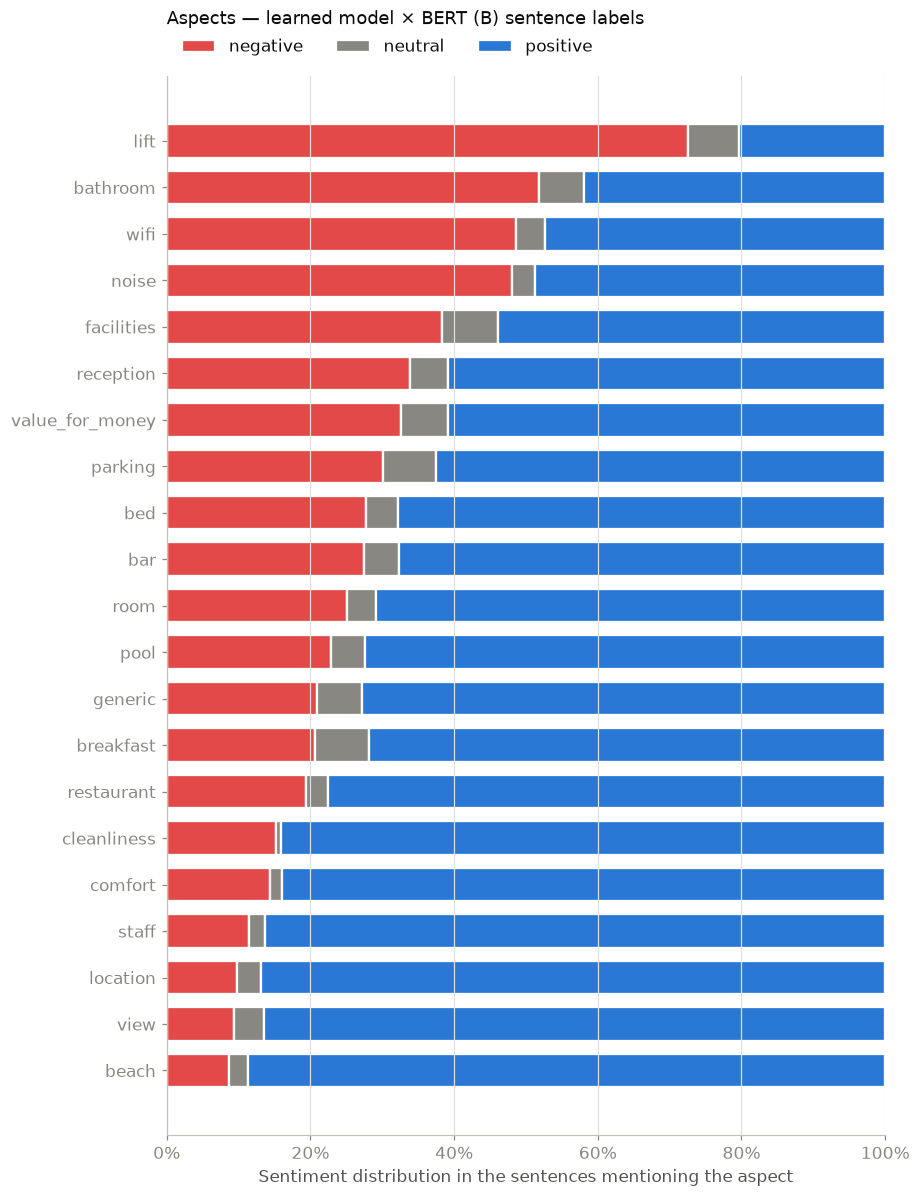

,share_model,share_keyword,agreement,cohen_kappa
aspect,,,,
location,0.2074,0.1510,0.9286,0.7584
staff,0.1623,0.1036,0.9282,0.6910
room,0.1407,0.1886,0.8850,0.5836
facilities,0.0987,0.0556,0.9029,0.3227
breakfast,0.0921,0.0965,0.9673,0.8085
cleanliness,0.0869,0.0779,0.9863,0.9093
bathroom,0.0460,0.0450,0.9871,0.8511
value_for_money,0.0332,0.0296,0.9856,0.7630
noise,0.0322,0.0255,0.9919,0.8557


15:49:01 | INFO    | src.evaluation | Table saved: 05_aspect_keyword_agreement_booking.csv


WindowsPath('C:/Users/seszt/Documents/BCE/7_felev/Szakdolgozat/THESIS/CODE/results/tables/05_aspect_keyword_agreement_booking.csv')

In [5]:
# HU: Aspektus × szentiment a TANULT aspektusokkal (vö. 04-es notebook: kulcsszavas változat).
# EN: Aspect × sentiment with the LEARNED aspects (cf. notebook 04: keyword version).
aspect_sent = asp.aspect_sentiment_table(sent_asp, label_col="B_label", aspects=ASPECT_NAMES,
                                         prefix="asp_", min_count=100)
display(aspect_sent); ev.save_table(aspect_sent, "05_aspect_sentiment_model")
asp.plot_aspect_sentiment(aspect_sent, "Aspects — learned model × BERT (B) sentence labels",
                          save_as="05_aspect_sentiment_model"); plt.show()

agreement = am.keyword_agreement(sent_asp.sample(min(50_000, len(sent_asp)), random_state=CFG.random_seed))
display(agreement); ev.save_table(agreement, "05_aspect_keyword_agreement_booking")

## 4. 2/b — Altémák aspektusonként / Subtopics per aspect

HU: A választott szentimentű (alapból **negatív**) mondatokon minden aspektusra külön témamodell: Sentence-BERT
beágyazás → UMAP → HDBSCAN → c-TF-IDF. A dicséretek altémáihoz állítsd `SENTIMENT = "positive"`-ra, és futtasd
újra innen (a fájlnevek a szentimentet is tartalmazzák).
EN: On sentences of the chosen sentiment (**negative** by default) a separate topic model per aspect: Sentence-BERT
embedding → UMAP → HDBSCAN → c-TF-IDF. For the subtopics of praise set `SENTIMENT = "positive"` and re-run from here
(file names include the sentiment).

In [15]:
SENTIMENT = "positive"
# HU: Az altéma-futás verziója (CFG.topic_version): minden alábbi kimenet nevében szerepel, így egy új
#     paraméterezés nem írja felül a korábbi (pl. v1) táblákat, ábrákat és kézi ellenőrzést.
# EN: Version of the subtopic run (CFG.topic_version): part of every output name below, so a new
#     parameter set does not overwrite earlier (e.g. v1) tables, figures and the manual check.
TAG = f"{SENTIMENT}_{CFG.topic_version}"
# HU: Kettős szűrés: a vendég a PANASZ-mezőbe írta, ÉS a (B) modell is negatívnak olvassa
#     (így kiesnek a panaszmezőbe írt "nothing, all perfect" típusú egységek).
# EN: Double filter: the guest wrote it into the COMPLAINT field AND the (B) model also reads it as
#     negative (this drops "nothing, all perfect" type units written into the complaint field).
subset = sent_asp[(sent_asp["field_polarity"] == SENTIMENT) & (sent_asp["B_label"] == SENTIMENT)
                  & (sent_asp["n_aspects"] > 0)].reset_index(drop=True)
print(f"{len(subset):,} {SENTIMENT} units with at least one aspect")

embeddings = tm.embed_sentences(subset["sentence"], cache_name=f"emb_{SENTIMENT}_units")

# HU: NEM-PANASZ egységek kiszűrése ("nothing", "no complaints", "all was perfect", "not the hotel's
#     fault"). A beágyazás a szűrés ELŐTT készül, így a cache érvényes marad; a sorokat utána
#     választjuk ki mindkettőből. Csak a negatív oldalon alkalmazzuk.
# EN: Remove NON-COMPLAINT units ("nothing", "no complaints", "all was perfect", "not the hotel's
#     fault"). The embedding is made BEFORE filtering, so the cache stays valid; rows are selected from
#     both afterwards. Applied on the negative side only.
if SENTIMENT == "negative":
    junk = pp.non_complaint_mask(subset["sentence"]).to_numpy()
    removed = subset.loc[junk, "sentence"].str.lower().str.strip(" .!").value_counts()
    print(f"Non-complaint units removed: {junk.sum():,} ({junk.mean():.1%})")
    display(removed.head(15).to_frame("count"))
    ev.save_table(removed.head(200).to_frame("count"), f"05_{TAG}_removed_non_complaints")
    subset, embeddings = subset.loc[~junk].reset_index(drop=True), embeddings[~junk]
print(f"{len(subset):,} units | embeddings: {embeddings.shape}")

70,353 positive units with at least one aspect


16:02:46 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/modules.json "HTTP/1.1 307 Temporary Redirect"
16:02:46 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transformers/all-MiniLM-L6-v2/1110a243fdf4706b3f48f1d95db1a4f5529b4d41/modules.json?%2Fsentence-transformers%2Fall-MiniLM-L6-v2%2Fresolve%2Fmain%2Fmodules.json=&etag=%22952a9b81c0bfd99800fabf352f69c7ccd46c5e43%22 "HTTP/1.1 200 OK"
16:02:46 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/config_sentence_transformers.json "HTTP/1.1 307 Temporary Redirect"
16:02:46 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transformers/all-MiniLM-L6-v2/1110a243fdf4706b3f48f1d95db1a4f5529b4d41/config_sentence_transformers.json?%2Fsentence-transformers%2Fall-MiniLM-L6-v2%2Fresolve%2Fmain%2Fconfig_sentence_transformers.j

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

16:02:47 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/processor_config.json "HTTP/1.1 404 Not Found"
16:02:47 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/preprocessor_config.json "HTTP/1.1 404 Not Found"
16:02:48 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/video_preprocessor_config.json "HTTP/1.1 404 Not Found"
16:02:48 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/preprocessor_config.json "HTTP/1.1 404 Not Found"
16:02:48 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
16:02:48 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transformers/all-Mini

70,353 units | embeddings: (70353, 384)


c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
16:04:45 | INFO    | src.topic_modeling | Topics: 26 | noise 24.1% -> 5.1% | NPMI -0.035 | diversity 0.777


,value
n_sentences,30000.0000
n_topics,26.0000
n_topics_before_merge,26.0000
n_merges,0.0000
min_cluster_size,300.0000
noise_share_before,0.2406
noise_share_after,0.0512
mean_coherence_npmi,-0.0350
topic_diversity,0.7769


,topic,size,share,label,top_terms,coherence_npmi,examples,merged_from
0,0,2588,0.086267,host / check / helpful,"host, check, helpful, hosts, friendly, reception, welcoming, owner, kind, welcome",0.007773,Our Host was friendly and helpful || Our hosts were extremely friendly and helpful || Our hosts were friendly and he...,
1,1,2259,0.075300,breakfast / breakfast good / good,"breakfast, breakfast good, good, good breakfast, delicious, great breakfast, buffet, breakfast great, excellent, great",0.061778,Breakfast was exceptionally good || breakfast were excellent || Breakfast was very nice,
2,2,2429,0.080967,room / rooms / spacious,"room, rooms, spacious, comfortable, clean, big, size, room spacious, large, room comfortable",0.044122,Very spacious rooms || The room was nice and spacious || nice and spacious rooms,
3,3,2096,0.069867,station / walk / close,"station, walk, close, location, city, train, town, walking, distance, train station",0.253864,Excellent location with a 10 minute walk into the city centre || Great location (5 min walk to the train and bus sta...,
4,4,1556,0.051867,definitely / come / recommend,"definitely, come, recommend, night, time, needed, return, enjoyed, trip, highly",-0.137219,We really enjoyed our stay || enjoyed our stay there || It was a great place to stay,
5,5,1701,0.056700,clean / comfortable / clean comfortable,"clean, comfortable, clean comfortable, modern, cleanliness, tidy, facilities, spacious, equipped, clean tidy",-0.125049,"clean and quite comfortable || Clean, comfortable in great location || comfortable and immaculately clean",
6,6,1559,0.051967,hostel / recommend / hotels,"hostel, recommend, hotels, located, accommodation, beautiful, best, great, clean, lovely",-0.139209,The location of the hotel is brilliant || The hotel is very nice || The hotel is in a great location,
7,7,1062,0.035400,bed / beds / comfortable,"bed, beds, comfortable, comfy, comfortable bed, bed comfortable, beds comfortable, comfortable beds, comfy bed, pillows",-0.118772,beds super comfortable || Beds were very comfortable || Beds were very comfortable,
8,8,1357,0.045233,view / balcony / views,"view, balcony, views, beautiful, terrace, sea, garden, amazing, lovely, stunning",0.183979,"The location and the view is stunning || Comfortable room and amazing view from terrace || Additionally, the balcony...",
9,9,972,0.032400,staff / staff friendly / helpful,"staff, staff friendly, helpful, friendly, staff helpful, welcoming, friendly helpful, accommodating, staff nice, sta...",0.051725,The staff were so friendly and helpful || The staff were really helpful and friendly || The staff were extremely hel...,


16:04:45 | INFO    | src.evaluation | Table saved: 05_positive_v5_topics_overview.csv
16:04:46 | INFO    | src.evaluation | Figure saved: 05_positive_v5_topics_overview.png


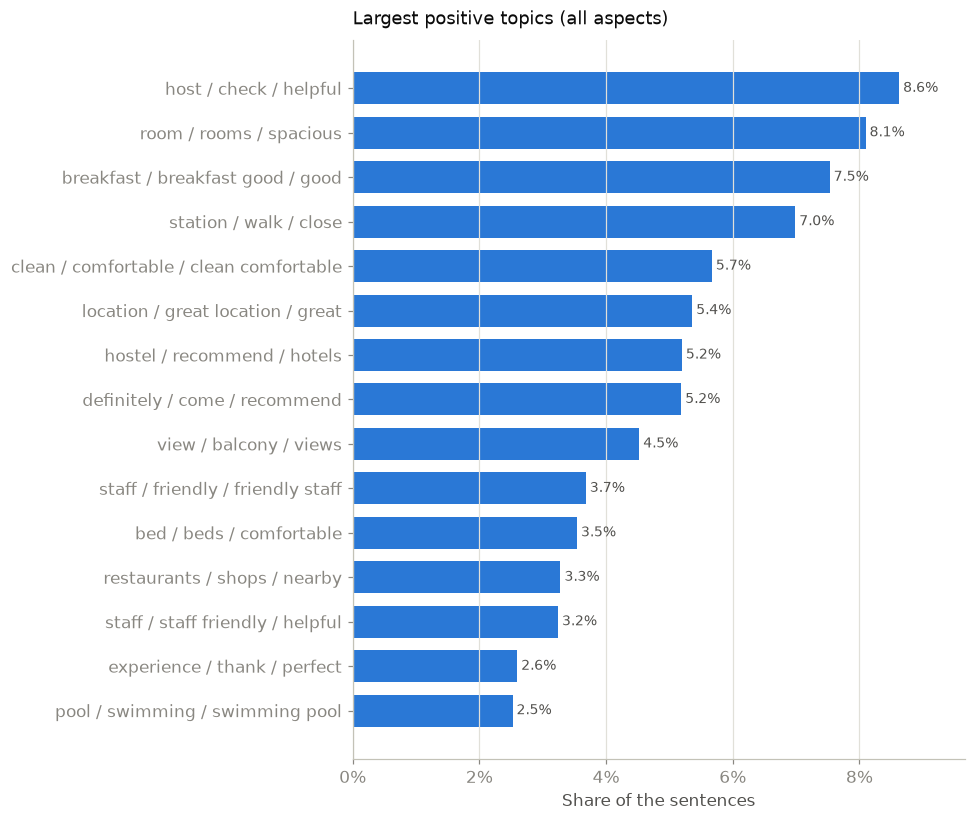

In [16]:
# HU: Áttekintő témamodell az összes ilyen mondaton (mintán) — aspektustól függetlenül.
# EN: Overview topic model on all such sentences (on a sample) — independent of the aspect.
rng = np.random.default_rng(CFG.random_seed)
overview_rows = np.sort(rng.choice(len(subset), size=min(30_000, len(subset)), replace=False))
overview = tm.fit_topics(subset["sentence"].iloc[overview_rows], embeddings[overview_rows])
display(pd.Series(overview.metrics).to_frame("value"))
display(overview.topic_info.head(20))
ev.save_table(overview.topic_info, f"05_{TAG}_topics_overview")
tm.plot_topic_sizes(overview.topic_info, f"Largest {SENTIMENT} topics (all aspects)", sentiment=SENTIMENT,
                    save_as=f"05_{TAG}_topics_overview"); plt.show()

### Finomság-vizsgálat / Granularity sweep

HU: Hány altémára bontsunk egy aspektust? A tapasztalat (v1, v2): egyetlen globális fürtméret nem jó minden
aspektusra — 1%-nál 19–21 apró, egymást átfedő altéma lett (pl. „rooms are small” és „the room was quite small” két
külön fürt), 3%-nál a fürdőszoba 18-ról **2** altémára ugrott (a HDBSCAN egy óriásfürtöt választott). Ezért (v3):
**finom fürtözés, majd a leghasonlóbb altémák összevonása** (BERTopic „topic reduction” elve), amíg legfeljebb
`CFG.subtopic_max_topics` marad, és nincs két `CFG.subtopic_merge_similarity` feletti hasonlóságú (közel-duplikátum)
téma. Az összevonás **átlagos kapcsolással** történik, és egy összevont altéma legfeljebb az aspektus
`CFG.subtopic_max_topic_share` részét (35%) teheti ki — enélkül (v3) „hógolyó” gyűjtőtémák keletkeztek (a zajnál a
forgalom, a zene és a szomszédok egyetlen 55%-os témává olvadt). A táblázat a három legnagyobb aspektuson mutatja a
lehetőségeket (`none` = nincs összevonás). Cél: kb.
**5–10 altéma**, a legnagyobb ≲ 50%, a koherencia (NPMI) ne romoljon. A UMAP aspektusonként egyszer fut (kb. 1–2 perc).

EN: How many subtopics should an aspect be split into? Experience (v1, v2): no single global cluster size suits every
aspect — at 1% there were 19–21 small, overlapping subtopics (e.g. "rooms are small" and "the room was quite small" as
two clusters), at 3% bathroom jumped from 18 to **2** subtopics (HDBSCAN picked one giant cluster). Hence (v3):
**fine clustering, then merging the most similar subtopics** (BERTopic "topic reduction" principle) until at most
`CFG.subtopic_max_topics` remain and no two topics exceed `CFG.subtopic_merge_similarity` (near-duplicates). The table
uses **average linkage**, and a merged subtopic may not exceed `CFG.subtopic_max_topic_share` (35%) of the aspect —
without that (v3) "snowball" catch-all topics appeared (for noise, traffic, music and neighbours melted into one 55%
topic). The table shows the options on the three largest aspects (`none` = no merging). Goal: about **5–10 subtopics**, largest ≲ 50%,
no worse coherence (NPMI). UMAP runs once per aspect (about 1–2 min). Set `RUN_SWEEP = False` once the setting is chosen.

In [17]:
RUN_SWEEP = True
if RUN_SWEEP:
    flag_counts = {a: int(subset[f"asp_{a}"].sum()) for a in ASPECT_NAMES if a not in ("generic",)}
    sweep_aspects = sorted(flag_counts, key=flag_counts.get, reverse=True)[:3]
    sweeps = []
    for aspect in sweep_aspects:
        rows = np.where(subset[f"asp_{aspect}"].to_numpy() == 1)[0]
        rows = np.sort(np.random.default_rng(CFG.random_seed).choice(
            rows, size=min(len(rows), CFG.topic_sample_per_aspect), replace=False))
        sweeps.append(tm.granularity_sweep(subset["sentence"].iloc[rows], embeddings[rows])
                        .reset_index().assign(aspect=aspect))
    sweep = pd.concat(sweeps, ignore_index=True).set_index(["aspect", "min_cluster_share", "max_topics"])
    display(sweep); ev.save_table(sweep, f"05_{TAG}_granularity_sweep")
print("Chosen subtopic settings:", tm.subtopic_params())

c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
16:06:05 | INFO    | src.topic_modeling | Topics: 24 | noise 30.7% -> 3.4% | NPMI -0.080 | diversity 0.696
16:06:09 | INFO    | src.topic_modeling | Topics: 12 | noise 30.7% -> 3.4% | NPMI 0.017 | diversity 0.792
16:06:13 | INFO    | src.topic_modeling | Topics: 10 | noise 30.7% -> 3.4% | NPMI -0.007 | diversity 0.810
16:06:18 | INFO    | src.topic_modeling | Topics: 8 | noise 30.7% -> 3.4% | NPMI -0.003 | diversity 0.825
16:06:22 | INFO    | src.topic_modeling | Topics: 6 | noise 30.7% -> 3.4% | NPMI 0.021 | diversity 0.850
16:06:25 | INFO    | src.topic_modeling | Topics: 13 | noise 32.9% -> 4.8% | NPMI 0.011 | diversity 0.700
16:06:29 | INFO    | src.topic_modeling | Topics: 12 | noise 32.9% -> 4.8% | NPMI 0.016 | diversity 0.733
16:06:33 | INFO    | src.topic_modeling | Top

min_cluster_size  n_topics_before_merge  n_topics  noise_share_before  mean_coherence_npmi  topic_diversity  largest_topic_share
aspect   min_cluster_share max_topics                                                                                                                                  
location 0.01              none                     150                     24        24              0.3065              -0.0800           0.6958               0.0939
                           12                       150                     24        12              0.3065               0.0166           0.7917               0.2971
                           10                       150                     24        10              0.3065              -0.0068           0.8100               0.2971
                           8                        150                     24         8              0.3065              -0.0026           0.8250               0.2971
                           6                        150                     24         6              0.3065               0.0209           0.8500               0.3245
         0.02              none                     300                     13        13              0.3295               0.0112           0.7000               0.1481
                           12                       300                     13        12              0.3295               0.0160           0.7333               0.1621
                           10                       300                     13        10              0.3295               0.0170           0.7700               0.2635
                           8                        300                     13         8              0.3295               0.0011           0.7375               0.2635
                           6                        300                     13         6              0.3295               0.0010           0.8000               0.2836
staff    0.01              none                     144                     31        31              0.2494              -0.2249           0.7065               0.0714
                           12                       144                     31        12              0.2494              -0.1231           0.7583               0.3273
                           10                       144                     31        10              0.2494              -0.1093           0.7500               0.3273
                           8                        144                     31         8              0.2494              -0.1023           0.7625               0.3273
                           6                        144                     31         6              0.2494              -0.1141           0.7333               0.3273
         0.02              none                     289                     18        18              0.2449              -0.1067           0.7111               0.1254
                           12                       289                     18        12              0.2449              -0.1107           0.6917               0.3256
                           10                       289                     18        10              0.2449              -0.1447           0.7700               0.3256
                           8                        289                     18         8              0.2449              -0.1240           0.7750               0.3256
                           6                        289                     18         6              0.2449              -0.1253           0.8167               0.3256
room     0.01              none                     105                     31        31              0.1971              -0.2861           0.6839               0.1334
                           12                       105                     31        12              0.1971              -0.1822           0.7333               0.2546
       

16:08:18 | INFO    | src.evaluation | Table saved: 05_positive_v5_granularity_sweep.csv


Chosen subtopic settings: {'min_cluster_share': 0.02, 'max_topics': 10, 'merge_similarity': 0.9, 'max_topic_share': 0.35}


16:08:47 | INFO    | src.topic_modeling | room             10553 sentences (model fitted on 10553)
c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
16:09:05 | INFO    | src.topic_modeling | Topics: 10 | noise 28.1% -> 1.4% | NPMI -0.051 | diversity 0.600
16:09:05 | INFO    | src.topic_modeling | location         18839 sentences (model fitted on 15000)
c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
16:09:34 | INFO    | src.topic_modeling | Topics: 10 | noise 32.9% -> 4.8% | NPMI 0.017 | diversity 0.770
16:09:34 | INFO    | src.topic_modeling | staff            14455 sentences (model fitted on 14455)
c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.ven

,n_sentences,n_topics_before_merge,n_topics,min_cluster_size,noise_share_before,noise_share_after,mean_coherence_npmi,topic_diversity
aspect,,,,,,,,
room,10553,16,10,211,0.2811,0.0141,-0.0515,0.6000
location,15000,13,10,300,0.3295,0.0479,0.0170,0.7700
staff,14455,18,10,289,0.2449,0.0379,-0.1447,0.7700
cleanliness,7649,16,10,152,0.1698,0.0038,-0.1187,0.7200
facilities,5395,20,10,107,0.0784,0.0234,-0.1087,0.9100
comfort,8083,21,10,161,0.2422,0.0066,-0.1166,0.6900
breakfast,6911,15,10,138,0.3166,0.0062,-0.0973,0.7400
bathroom,1961,16,10,40,0.2101,0.0005,-0.1542,0.8000
noise,1660,12,10,40,0.2000,0.0042,-0.2313,0.7600


16:14:07 | INFO    | src.evaluation | Table saved: 05_positive_v5_subtopic_quality.csv
16:14:07 | INFO    | src.evaluation | Table saved: 05_positive_v5_subtopics.csv


Main aspects: ['location', 'staff', 'room', 'comfort', 'cleanliness', 'breakfast', 'facilities', 'bed', 'view', 'value_for_money', 'bathroom', 'reception', 'noise', 'restaurant', 'pool', 'beach', 'parking', 'bar', 'wifi']


16:14:14 | INFO    | src.evaluation | Figure saved: 05_positive_v5_subtopics_by_aspect.png


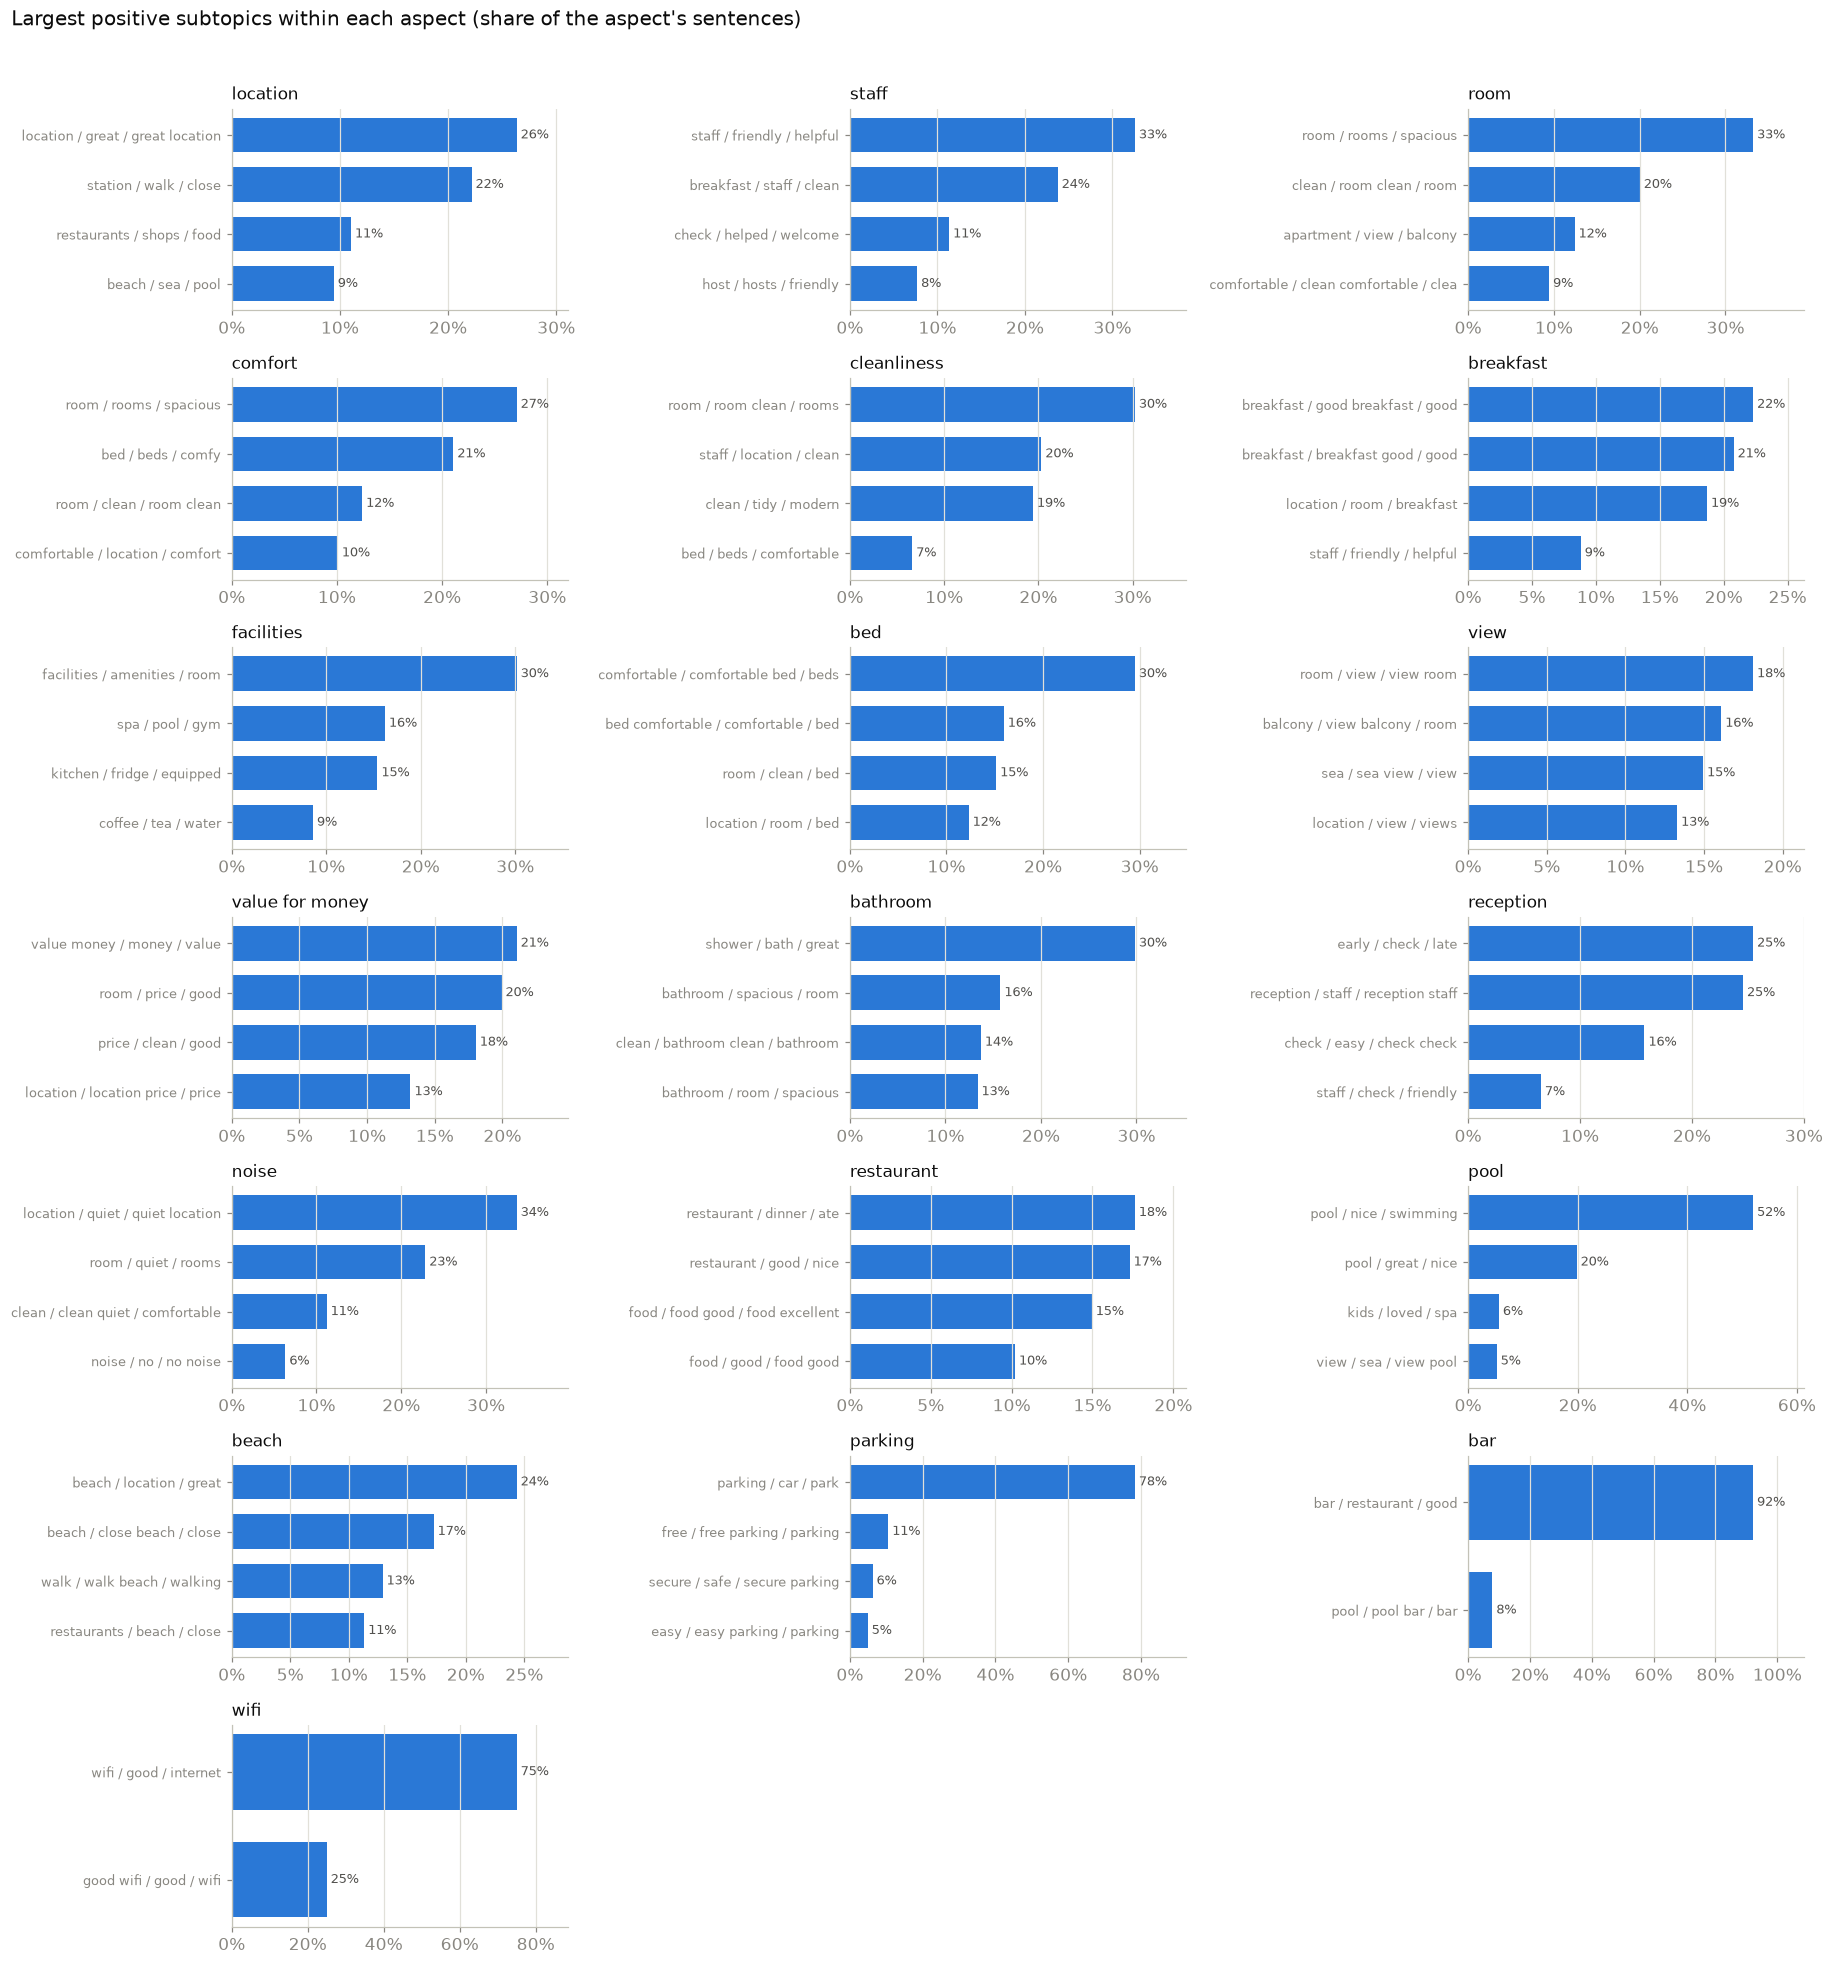

In [18]:
topic_table, assignments, topic_summary = tm.fit_subtopics_per_aspect(subset, embeddings, ASPECT_NAMES)
display(topic_summary)
ev.save_table(topic_summary, f"05_{TAG}_subtopic_quality")
# HU: A legtöbb mondatú, legalább egy altémát adó aspektusok. / EN: Aspects with most sentences and at least one subtopic.
MAIN_ASPECTS = (topic_summary[topic_summary["n_topics"] > 0]
                .sort_values("n_sentences", ascending=False).index.tolist())
print("Main aspects:", MAIN_ASPECTS)
ev.save_table(topic_table, f"05_{TAG}_subtopics")
dl.write_frame(assignments.assign(review_id=subset["review_id"].iloc[assignments["row"]].to_numpy(),
                                  sentence=subset["sentence"].iloc[assignments["row"]].to_numpy()),
               PATHS.labels / f"subtopic_assignments_{TAG}")

tm.plot_aspect_subtopics(topic_table, top_k=4, sentiment=SENTIMENT,
                         save_as=f"05_{TAG}_subtopics_by_aspect"); plt.show()

In [19]:
# HU: Olvasd el az altémákat a példamondatokkal! / EN: Read the subtopics with the example sentences!
for aspect in MAIN_ASPECTS[:4]:
    print(f"\n=== {aspect} ===")
    for _, r in topic_table[topic_table["aspect"] == aspect].head(6).iterrows():
        print(f"  [{r['topic']}] {r['label']}  ({r['share_within_aspect']:.0%}, NPMI {r['coherence_npmi']:.2f})")
        if r["merged_from"]:
            print(f"       merged from: {r['merged_from'][:150]}")
        print(f"       e.g. {r['examples'].split(' || ')[0][:150]}")


=== location ===
  [0] location / great / great location  (26%, NPMI -0.09)
       merged from: location / location good / location great + great location / location / great + location / beautiful / perfect
       e.g. A great location
  [1] station / walk / close  (22%, NPMI 0.07)
       merged from: city / walk / town + station / train / train station
       e.g. Excellent location with a 10 minute walk into the city centre
  [2] restaurants / shops / food  (11%, NPMI 0.09)
       e.g. shops and restaurants nearby
  [3] beach / sea / pool  (9%, NPMI -0.03)
       e.g. The location is fantastic and close to the Beach
  [4] located / location / city  (7%, NPMI -0.06)
       e.g. The hotel has a great location
  [5] airport / close airport / shuttle  (6%, NPMI 0.03)
       e.g. Perfect place to stay near the airport

=== staff ===
  [0] staff / friendly / helpful  (33%, NPMI -0.09)
       merged from: staff / staff friendly / helpful + helpful staff / helpful / staff + staff / staff gr

In [20]:
# HU: OPCIONÁLIS: beszédes nevek a dolgozatba (a témaszámokat a fenti listából vedd).
# EN: OPTIONAL: meaningful names for the thesis (take the topic numbers from the list above).
TOPIC_NAMES = {
    # ("bathroom", 0): "no hot water",
    # ("noise", 1): "thin walls / neighbours",
}
if TOPIC_NAMES:
    topic_table, assignments = tm.rename_topics(topic_table, assignments, TOPIC_NAMES)
    ev.save_table(topic_table, f"05_{TAG}_subtopics")

### Stabilitás / Stability

HU: Ugyanaz a modell három különböző véletlen kezdőértékkel a három legnagyobb aspektuson. A korrigált Rand-index
(ARI) 0,5 felett azt jelzi, hogy a témák nem a véletlen termékei.
EN: The same model with three different random seeds on the three largest aspects. An adjusted Rand index (ARI)
above 0.5 shows that the topics are not products of chance.

In [21]:
stability_rows = []
for aspect in MAIN_ASPECTS[:3]:
    rows = np.where(subset[f"asp_{aspect}"].to_numpy() == 1)[0]
    rows = np.sort(np.random.default_rng(CFG.random_seed).choice(
        rows, size=min(len(rows), CFG.topic_sample_per_aspect), replace=False))
    table = tm.topic_stability(subset["sentence"].iloc[rows], embeddings[rows], **tm.subtopic_params())
    stability_rows.append({"aspect": aspect, "mean_pairwise_ari": table.attrs["mean_pairwise_ari"],
                           "n_topics_per_seed": table["n_topics"].tolist()})
stability = pd.DataFrame(stability_rows).set_index("aspect").round(3)
display(stability); ev.save_table(stability, f"05_{TAG}_subtopic_stability")

c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
16:16:19 | INFO    | src.topic_modeling | Topics: 10 | noise 32.9% -> 4.8% | NPMI 0.017 | diversity 0.770
c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
16:16:48 | INFO    | src.topic_modeling | Topics: 10 | noise 33.4% -> 4.7% | NPMI 0.021 | diversity 0.740
c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
16:17:17 | INFO    | src.topic_modeling | Topics: 10 | noise 32.2% -> 4.5% | NPMI 0.019 | diversity 0.760
16:17:17 | INFO    | src.topic_modeling | Stab

,mean_pairwise_ari,n_topics_per_seed
aspect,,
location,0.744,"[10, 10, 10]"
staff,0.696,"[10, 10, 10]"
room,0.554,"[10, 10, 10]"


16:19:33 | INFO    | src.evaluation | Table saved: 05_positive_v5_subtopic_stability.csv


WindowsPath('C:/Users/seszt/Documents/BCE/7_felev/Szakdolgozat/THESIS/CODE/results/tables/05_positive_v5_subtopic_stability.csv')

## 5. Panasztérkép / Complaint map

HU: Egy aspektus altémáinak aránya szegmensenként, liftként: 1 felett az altéma az adott szegmensben gyakoribb,
mint átlagosan. Például: a szállodákban a „vékony fal” vagy az apartmanokban a „nincs meleg víz” a jellemzőbb?
Minden cellára arány-z-próba (szegmens vs. többi) Benjamini–Hochberg-korrekcióval. `*` = szignifikáns ÉS legalább 20%-os
eltérés (|lift − 1| ≥ 0,2), halvány = nem. Kis szegmensben a nagy lift is lehet véletlen, nagy mintán pedig egy 1,06-os
eltérés is szignifikáns — a dolgozatban csak a csillagos cellákat értelmezd. Színek: az átlagnál gyakoribb altéma a
szentiment színét kapja (panasz = piros, dicséret = kék), a ritkább szürke.
EN: Share of an aspect's subtopics per segment, as lift: above 1 the subtopic is more common in that segment than on
average. E.g.: is "thin walls" more typical in hotels, or "no hot water" in apartments?
A two-proportion z-test per cell (segment vs. rest) with Benjamini–Hochberg correction. `*` = significant AND at least a
20% difference (|lift − 1| ≥ 0.2), faded = not. In a small segment even a large lift can be chance, on a large sample even
1.06 is significant — interpret only the starred cells in the thesis. Colours: a subtopic more common than average gets
the sentiment colour (complaint = red, praise = blue), a rarer one grey.

16:20:12 | INFO    | src.evaluation | Table saved: 05_positive_v5_map_location_by_accommodation_type.csv


,segment,subtopic,lift,count,segment_n,q,significant,notable
59,Resort,beach / sea / pool,3.848,211,574,0.0000,True,True
15,Apartment,clean / comfortable / cleanliness,1.563,97,1967,0.0000,True,True
51,Motel,beach / sea / pool,1.513,76,526,0.0003,True,True
3,ApartHotel,beach / sea / pool,1.417,124,916,0.0001,True,True
50,Motel,restaurants / shops / food,1.351,82,526,0.0086,True,True
44,Hotel,located / location / city,1.324,1004,9718,0.0000,True,True
33,Hostel,station / walk / close,1.300,193,640,0.0001,True,True
45,Hotel,airport / close airport / shuttle,1.247,772,9718,0.0000,True,True


16:20:15 | INFO    | src.evaluation | Figure saved: 05_positive_v5_map_location_by_accommodation_type.png


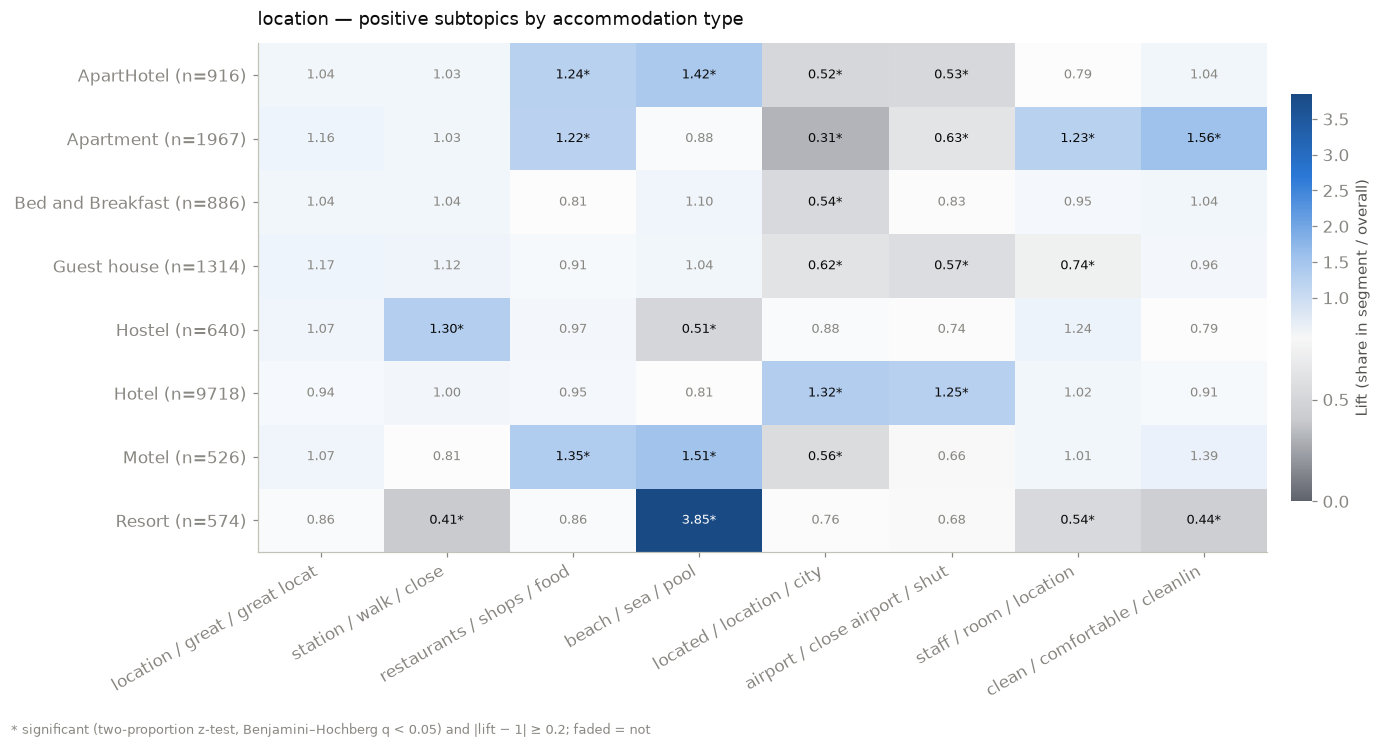

16:20:16 | INFO    | src.evaluation | Table saved: 05_positive_v5_map_location_by_accommodation_country.csv


,segment,subtopic,lift,count,segment_n,q,significant,notable
19,Greece,beach / sea / pool,2.685,175,721,0.0000,True,True
33,Japan,station / walk / close,1.812,256,604,0.0000,True,True
43,Spain,beach / sea / pool,1.524,117,849,0.0000,True,True
5,Australia,staff / room / location,1.514,82,830,0.0002,True,True
36,Japan,located / location / city,1.375,58,604,0.0200,True,True
9,France,station / walk / close,1.360,216,679,0.0000,True,True
54,United Kingdom,airport / close airport / shuttle,1.337,225,2809,0.0000,True,True
34,Japan,restaurants / shops / food,1.323,91,604,0.0081,True,True


16:20:19 | INFO    | src.evaluation | Figure saved: 05_positive_v5_map_location_by_accommodation_country.png


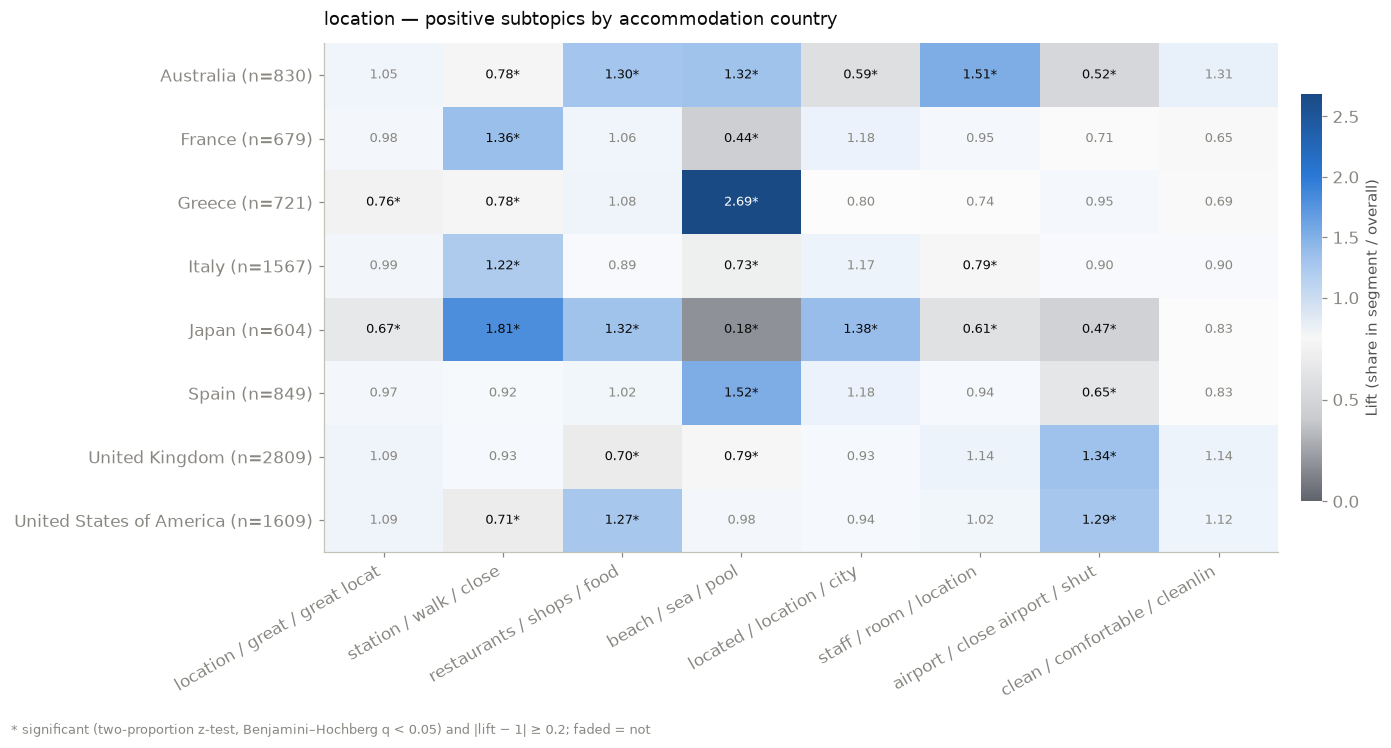

16:20:20 | INFO    | src.evaluation | Table saved: 05_positive_v5_map_staff_by_accommodation_type.csv


,segment,subtopic,lift,count,segment_n,q,significant,notable
11,Apartment,host / hosts / friendly,3.952,308,1052,0.0000,True,True
19,Bed and Breakfast,host / hosts / friendly,2.898,222,1034,0.0000,True,True
27,Guest house,host / hosts / friendly,2.546,225,1193,0.0000,True,True
29,Guest house,lady / especially / gave,1.786,74,1193,0.0000,True,True
21,Bed and Breakfast,lady / especially / gave,1.754,63,1034,0.0000,True,True
10,Apartment,check / helped / welcome,1.605,194,1052,0.0000,True,True
13,Apartment,lady / especially / gave,1.560,57,1052,0.0009,True,True
5,ApartHotel,lady / especially / gave,1.547,26,484,0.0428,True,True


16:20:23 | INFO    | src.evaluation | Figure saved: 05_positive_v5_map_staff_by_accommodation_type.png


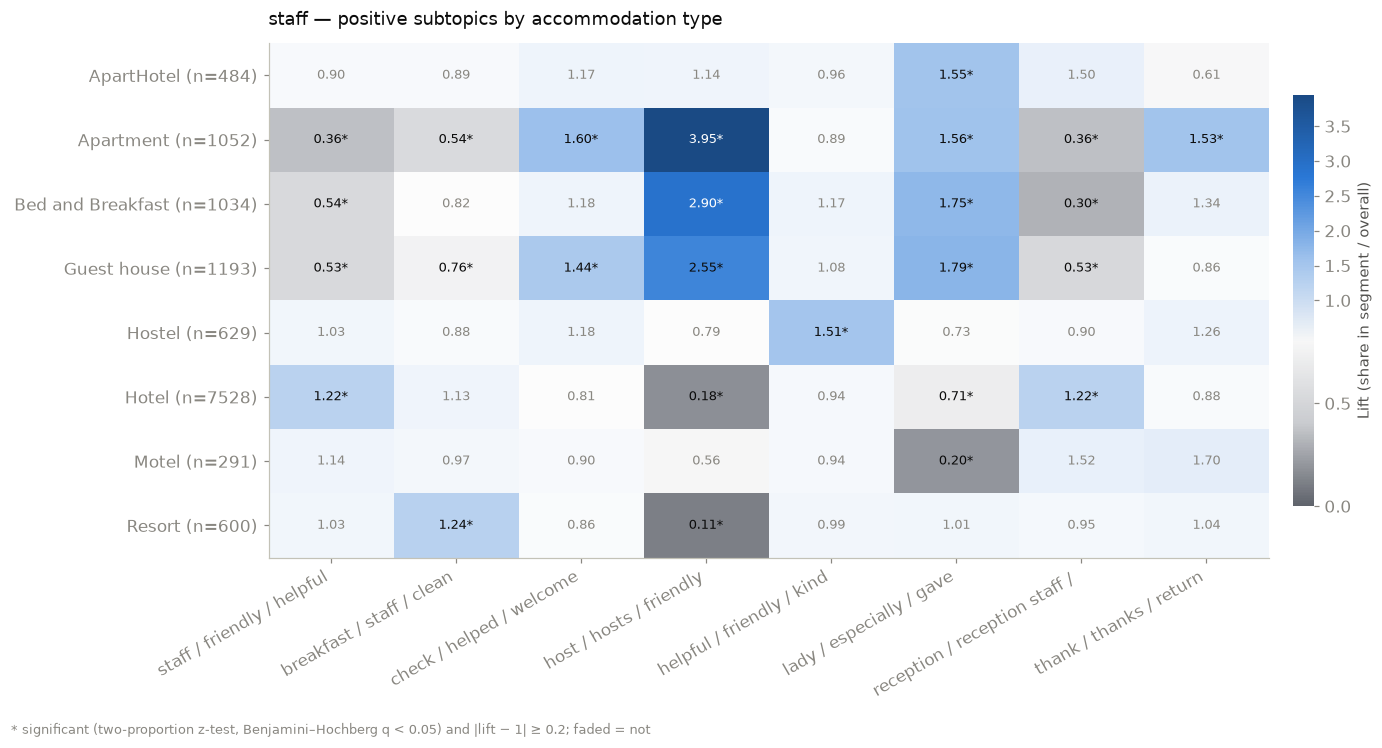

16:20:24 | INFO    | src.evaluation | Table saved: 05_positive_v5_map_staff_by_accommodation_country.csv


,segment,subtopic,lift,count,segment_n,q,significant,notable
38,Spain,reception / reception staff / staff reception,1.939,36,620,0.0001,True,True
14,France,reception / reception staff / staff reception,1.922,24,417,0.0025,True,True
21,Greece,lady / especially / gave,1.827,42,638,0.0001,True,True
27,Italy,host / hosts / friendly,1.786,180,1214,0.0000,True,True
19,Greece,host / hosts / friendly,1.661,88,638,0.0000,True,True
29,Italy,lady / especially / gave,1.531,67,1214,0.0005,True,True
23,Greece,thank / thanks / return,1.526,27,638,0.0478,True,True
20,Greece,helpful / friendly / kind,1.518,58,638,0.0022,True,True


16:20:27 | INFO    | src.evaluation | Figure saved: 05_positive_v5_map_staff_by_accommodation_country.png


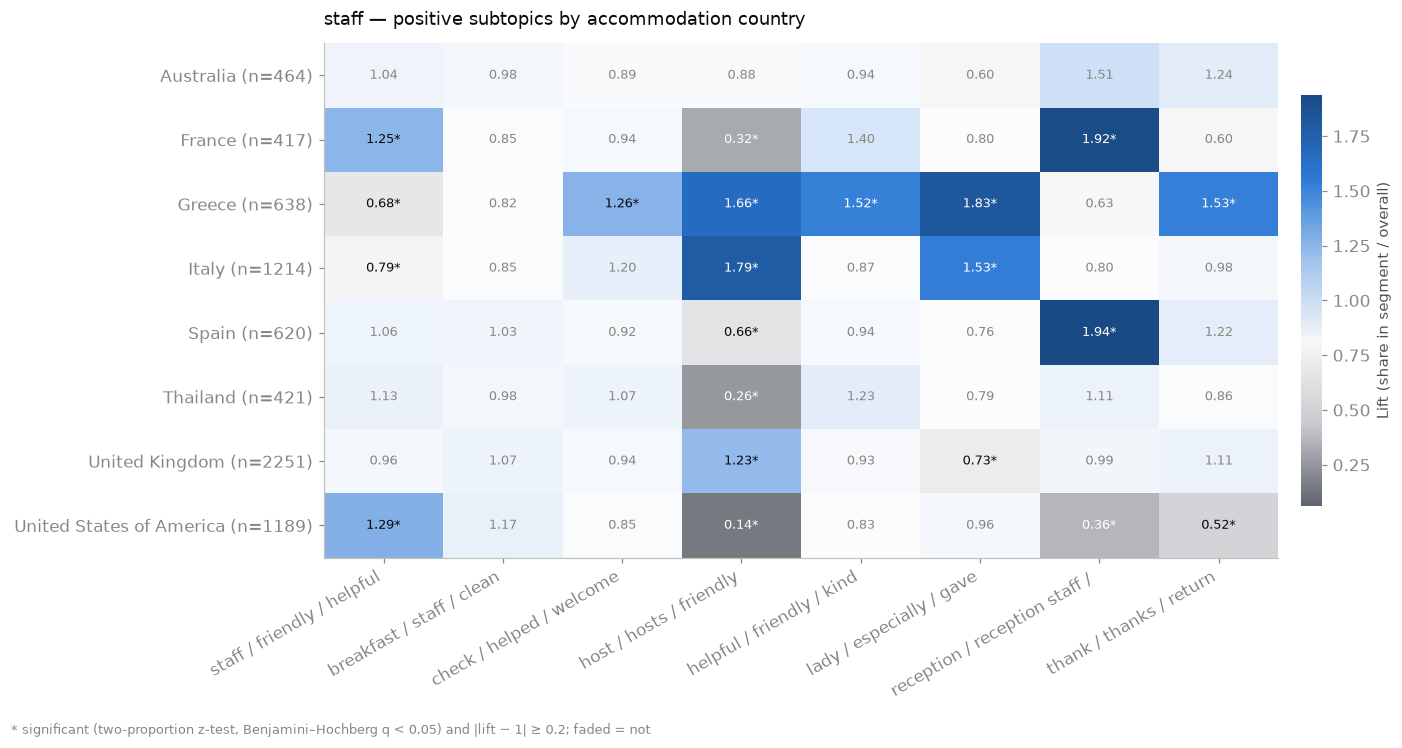

16:20:27 | INFO    | src.evaluation | Table saved: 05_positive_v5_map_room_by_accommodation_type.csv


,segment,subtopic,lift,count,segment_n,q,significant,notable
15,Apartment,spacious / clean spacious / space,2.961,91,924,0.0000,True,True
10,Apartment,apartment / view / balcony,2.654,309,924,0.0000,True,True
22,Bed and Breakfast,breakfast / good / good breakfast,2.415,53,595,0.0000,True,True
7,ApartHotel,spacious / clean spacious / space,1.958,31,476,0.0002,True,True
21,Bed and Breakfast,bathroom / shower / room bathroom,1.951,45,595,0.0000,True,True
2,ApartHotel,apartment / view / balcony,1.801,108,476,0.0000,True,True
51,Motel,comfortable / clean comfortable / clean,1.725,59,370,0.0000,True,True
37,Hostel,bathroom / shower / room bathroom,1.703,20,303,0.0308,True,True


16:20:30 | INFO    | src.evaluation | Figure saved: 05_positive_v5_map_room_by_accommodation_type.png


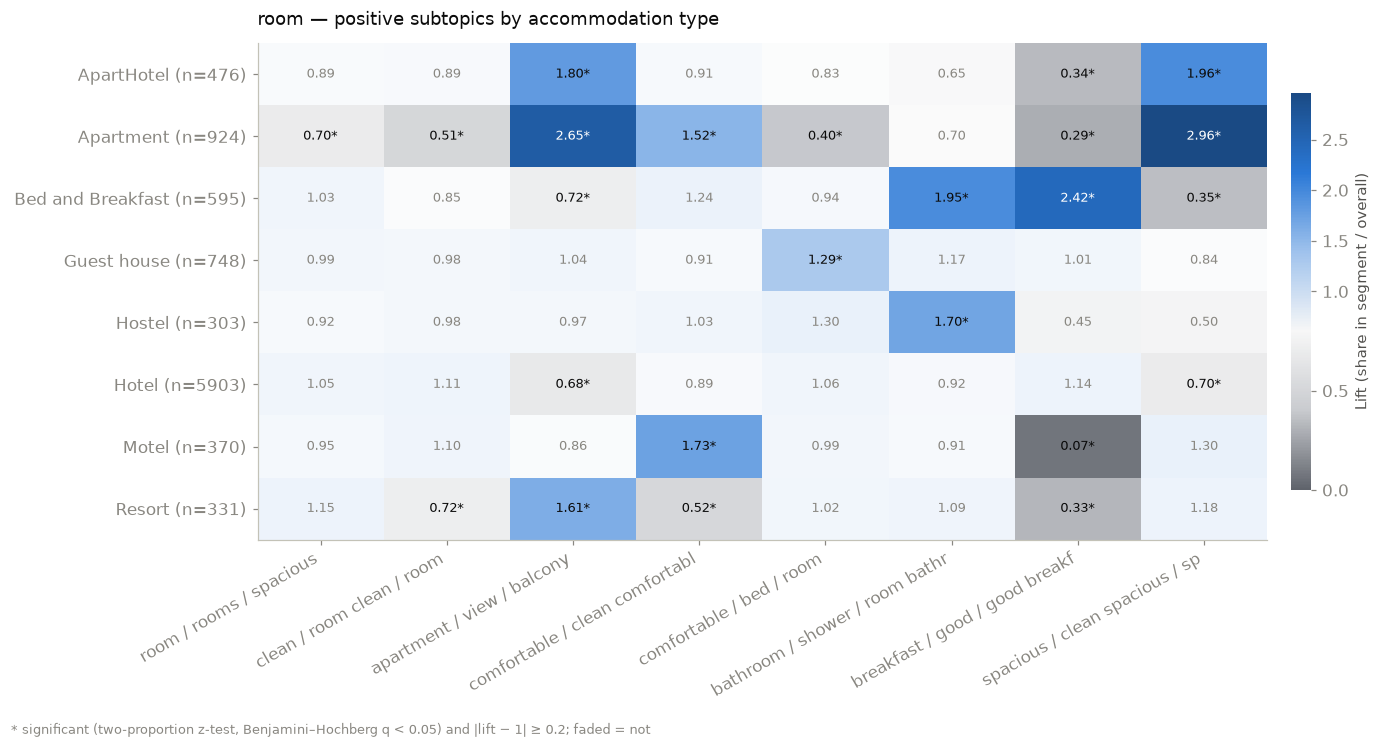

16:20:31 | INFO    | src.evaluation | Table saved: 05_positive_v5_map_room_by_accommodation_country.csv


,segment,subtopic,lift,count,segment_n,q,significant,notable
34,Spain,apartment / view / balcony,1.829,90,400,0.0000,True,True
18,Greece,apartment / view / balcony,1.758,72,333,0.0000,True,True
7,Australia,spacious / clean spacious / space,1.700,32,538,0.0084,True,True
54,United Kingdom,breakfast / good / good breakfast,1.620,122,2083,0.0000,True,True
26,Italy,apartment / view / balcony,1.388,125,732,0.0003,True,True
50,United Kingdom,apartment / view / balcony,0.796,204,2083,0.0002,True,True
58,United States of America,apartment / view / balcony,0.696,102,1191,0.0002,True,True
27,Italy,comfortable / clean comfortable / clean,0.688,51,732,0.0116,True,True


16:20:34 | INFO    | src.evaluation | Figure saved: 05_positive_v5_map_room_by_accommodation_country.png


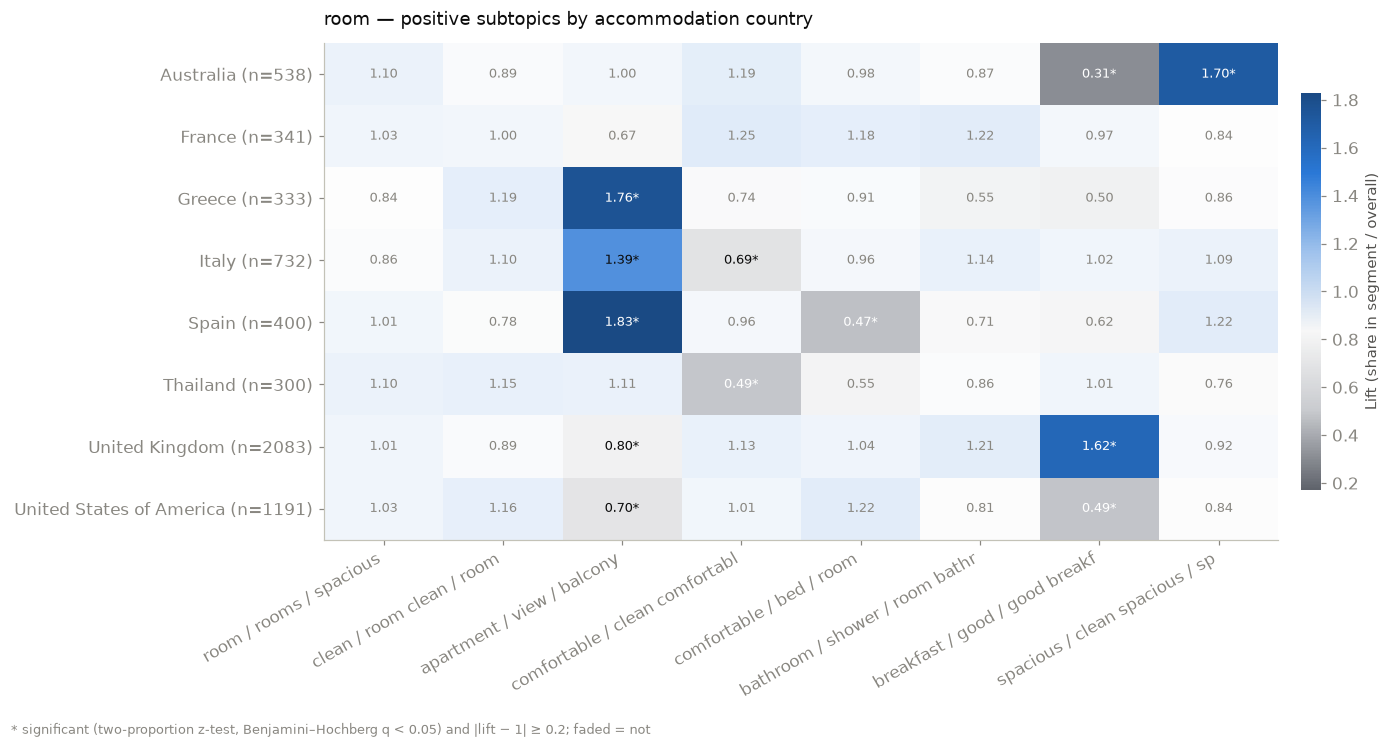

In [22]:
for aspect in MAIN_ASPECTS[:3]:
    for segment in ["accommodation_type", "accommodation_country"]:
        lift = tm.segment_table(assignments, subset, aspect, segment, min_count=50, top_segments=8)
        if lift.empty:
            continue
        long = tm.segment_long_table(lift)
        ev.save_table(long, f"05_{TAG}_map_{aspect}_by_{segment}")
        display(long[long["notable"]].head(8))
        tm.plot_segment_heatmap(lift, f"{aspect.replace('_', ' ')} — {SENTIMENT} subtopics by {segment.replace('_', ' ')}",
                                save_as=f"05_{TAG}_map_{aspect}_by_{segment}", sentiment=SENTIMENT)
        plt.show()

## 6. Kézi ellenőrzés / Manual check

HU: Témánként 20 véletlen mondat Excelben; a `fits` oszlopba 1 (illik a témához) vagy 0 kerül. Az első futás
exportál, a kitöltés után a második futás kiszámolja a témánkénti pontosságot. (Kb. 1–2 óra a nagyobb aspektusokra.)
EN: 20 random sentences per topic in Excel; put 1 (fits the topic) or 0 into the `fits` column. The first run exports,
after filling it in the second run computes the per-topic precision. (About 1–2 hours for the larger aspects.)

In [23]:
check_file = PATHS.annotation / f"topic_check_{TAG}.xlsx"
if not check_file.exists():
    top_aspects = MAIN_ASPECTS[:4]
    tm.export_topic_check(topic_table[topic_table["aspect"].isin(top_aspects)],
                          assignments[assignments["aspect"].isin(top_aspects)], subset,
                          filename=check_file.name)
    print("Exported — fill in the 'fits' column, then re-run this cell.")
else:
    precision = tm.evaluate_topic_check(check_file.name)
    display(precision); ev.save_table(precision, f"05_{TAG}_topic_precision")

16:23:20 | INFO    | src.topic_modeling | Topic check exported: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\data\annotation\topic_check_positive_v5.xlsx (800 sentences)


Exported — fill in the 'fits' column, then re-run this cell.


---
## Összefoglalás / Summary

| Kimenet / Output | Mire jó? / Purpose |
|---|---|
| `05_aspect_keyword_vs_model` (tábla + ábra) | **2/a mérése:** tanult modell vs. kulcsszólista, emberi címkén |
| `05_aspect_model_test_report` | aspektusonkénti precision / recall / F1 |
| `05_aspect_sentiment_model` | aspektus × szentiment a tanult aspektusokkal |
| `05_<sentiment>_<verzió>_removed_non_complaints` | kiszűrt nem-panasz egységek („nothing”, „all good”) |
| `05_<sentiment>_<verzió>_granularity_sweep` | az altéma-finomság (fürtméret × összevonás) választásának indoklása |
| `05_<sentiment>_<verzió>_subtopics` + `_subtopics_by_aspect.png` | **2/b:** altémák aspektusonként |
| `05_<sentiment>_<verzió>_subtopic_quality`, `_stability` | koherencia, diverzitás, stabilitás |
| `05_<sentiment>_<verzió>_map_*` | **panasztérkép** szegmensenként (a 8 legnagyobb altéma; db, lift, q, szignifikáns, jelentős) |
| `05_<sentiment>_<verzió>_topic_precision` | kézi ellenőrzés: témánkénti pontosság |

HU: A `<verzió>` = `CFG.topic_version` (most `v5`). A régebbi, verzió nélküli `05_negative_*` fájlok a v1 futás
eredményei — a dolgozat 3.4 fejezetében az előtte–utána összevetéshez hasznosak.
EN: `<verzió>` = `CFG.topic_version` (now `v5`). The older `05_negative_*` files without a version are the results of
run v1 — useful for the before/after comparison in chapter 3.4.